In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
import pickle
from tensorflow.keras.layers import Embedding, SimpleRNN
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
X = []
y = []
for i in range(1,100):
  X.append([i,i+1, i+2])
  y.append(i+3)
X = np.array(X)
y = np.array(y)
print(X[:5])
print(y[:5])

[[1 2 3]
 [2 3 4]
 [3 4 5]
 [4 5 6]
 [5 6 7]]
[4 5 6 7 8]


In [ ]:
#Reshape
X = np.reshape(X, (X.shape[0], X.shape[1], 1))
print(X[:5])

[[[1]
  [2]
  [3]]

 [[2]
  [3]
  [4]]

 [[3]
  [4]
  [5]]

 [[4]
  [5]
  [6]]

 [[5]
  [6]
  [7]]]


In [ ]:
X = X.reshape(X.shape[0],X.shape[1],1)
print(X.shape)

(99, 3, 1)


In [ ]:
# Simple RNN model
model = Sequential([
    SimpleRNN(20, input_shape=(3,1),activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 20)             │           440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 461 (1.80 KB)

 Trainable params: 461 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(X,y,epochs=500,verbose=0)

In [ ]:
test=np.array([10,11,12])
test = test.reshape(1,3,1)
prediction=model.predict(test)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
[[13.000516]]


In [ ]:
!pip install transformers sentencepiece -q

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "Helsinki-NLP/opus-mt-en-fr"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

In [ ]:
sentence = "I love deep learning"
input_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = model.generate(input_ids)
translated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(translated_text)

J'adore l'apprentissage profond


In [ ]:
sentence = "Artificial intelligence is changing the world"

input_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = model.generate(input_ids)
translated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("English :", sentence)
print("French  :", translated_text)

English : Artificial intelligence is changing the world
French  : L'intelligence artificielle change le monde


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Recreate X and y as defined earlier
X = []
y = []
for i in range(1, 100):
    X.append([i, i+1, i+2])
    y.append(i+3)
X = np.array(X)
y = np.array(y)
X = X.reshape(X.shape[0], X.shape[1], 1)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (79, 3, 1)
y_train shape: (79,)
X_test shape: (20, 3, 1)
y_test shape: (20,)


In [ ]:
def make_windows(series, window, horizon=1, target_col=0):
    # series: (T,) or (T, F).  Returns X: (n, window, F) and y: (n, horizon).
    s = np.asarray(series, dtype="float32")
    if s.ndim == 1:
        s = s[:, None]
    n = len(s) - window - horizon + 1
    X = np.stack([s[i:i + window] for i in range(n)])
    y = np.stack([s[i + window:i + window + horizon, target_col] for i in range(n)])
    return X, y


def chronological_split(X, y, val=0.15, test=0.15):
    # Split in time order: oldest data for training, newest for testing. No shuffling.
    n = len(X)
    i_val, i_test = int(n * (1 - val - test)), int(n * (1 - test))
    return (X[:i_val], y[:i_val]), (X[i_val:i_test], y[i_val:i_test]), (X[i_test:], y[i_test:])


class RelativeScaler:
    # Window-relative scaling: subtract each window's last value, divide by one global scale.
    # Fit on training data only. Targets are taken to be feature 0.
    def fit(self, X):
        self.scale_ = float(np.std(X - X[:, -1:, :])) or 1.0
        return self

    def transform(self, X, y=None):
        Xr = (X - X[:, -1:, :]) / self.scale_
        if y is None:
            return Xr
        return Xr, (y - X[:, -1, :1]) / self.scale_

    def inverse_y(self, X, y_scaled):
        return y_scaled * self.scale_ + X[:, -1, :1]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

CELLS={"simple": layers.SimpleRNN, "lstm":layers.LSTM, "gru":layers.GRU}
def build_rnn(task, input_shape=None, * , cell="lstm", units =(65), bidirectional=False, dropout= 0.2, n_outputs=1, vocab_size=None,embed_dim=64, mask_zero=None,
              lr=1e-3, name=None):
    if task not in ("regression", "binary", "multiclass", "language_model"):
        raise ValueError(f"unknown task: {task}")
    seq_out = task == "language_model"

    if vocab_size:                                          # token IDs -> vectors
        inputs = keras.Input(shape=(None,), dtype="int32")
        mask = (not seq_out) if mask_zero is None else mask_zero   # 0 = padding, except in LMs
        x = layers.Embedding(vocab_size, embed_dim, mask_zero=mask)(inputs)
    else:                                                   # real-valued features
        inputs = keras.Input(shape=input_shape)
        x = inputs

    for i, u in enumerate(units):
        last = i == len(units) - 1
        rnn = CELLS[cell](u, return_sequences=(not last) or seq_out)
        x = layers.Bidirectional(rnn)(x) if bidirectional else rnn(x)
        if dropout:
            x = layers.Dropout(dropout)(x)

    if task == "regression":
        outputs, loss, metrics = layers.Dense(n_outputs)(x), "mse", ["mae"]
    elif task == "binary":
        outputs, loss, metrics = layers.Dense(1, activation="sigmoid")(x), "binary_crossentropy", ["accuracy"]
    elif task == "multiclass":
        outputs, loss, metrics = (layers.Dense(n_outputs, activation="softmax")(x),
                                  "sparse_categorical_crossentropy", ["accuracy"])
    else:  # language_model: raw scores (logits) for every token at every position
        outputs = layers.Dense(vocab_size)(x)
        loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        metrics = ["accuracy"]

    model = keras.Model(inputs, outputs, name=name or f"{cell}_{task}")
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss=loss, metrics=metrics)
    return model

build_rnn("regression", (3, 1), cell="lstm", units=(32,)).summary()

Model: "lstm_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 3, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import matplotlib.pyplot as plt

def fit(model, x, y, validation_data, max_epochs, batch_size=64, patience=8, verbose=0):
    cbs=[
      keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 2))
    ]
    h=model.fit(x, y, validation_data=validation_data, batch_size=batch_size, epochs=max_epochs, callbacks=cbs, verbose=verbose)
    return h

def plot_history(h, title=""):
    metric = next((k for k in h.history if k not in ("loss", "learning_rate") and not k.startswith("val_")), None)
    keys = ["loss"] + ([metric] if metric else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(5.5 * len(keys), 3.5))
    for ax, k in zip(np.atleast_1d(axes), keys):
        ax.plot(h.history[k], label="train")
        ax.plot(h.history["val_" + k], label="validation")
        ax.set_title(f"{title} {k}"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

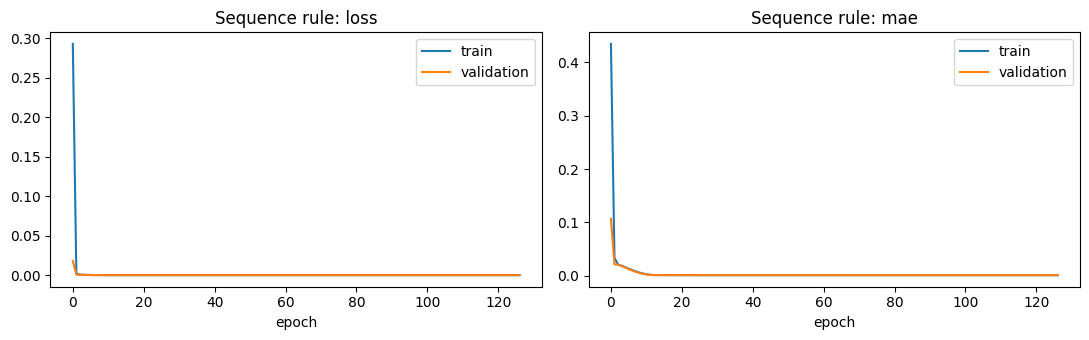

Held-out test MAE: 0.005


In [ ]:
import numpy as np
from tensorflow import keras

# Instantiate the random number generator and set-seed helper
rng = np.random.default_rng(seed=42)

def set_seed(seed=42):
    keras.utils.set_random_seed(seed)

def arithmetic_sequences(n, length=3, start=(0, 100), step=(-5, 5)):
    starts = rng.uniform(*start, size=n)
    steps = rng.integers(step[0], step[1] + 1, size=n)
    seq = starts[:, None] + steps[:, None] * np.arange(length + 1)
    return seq[:, :length, None].astype("float32"), seq[:, length:].astype("float32")

X_all, y_all = arithmetic_sequences(6000)
(Xtr, ytr), (Xva, yva), (Xte, yte) = chronological_split(X_all, y_all)   # data is i.i.d., so order is random anyway

scaler_seq = RelativeScaler().fit(Xtr)
Xtr_s, ytr_s = scaler_seq.transform(Xtr, ytr)
Xva_s, yva_s = scaler_seq.transform(Xva, yva)

set_seed()
seq_model = build_rnn("regression", (3, 1), cell="lstm", units=(32,), dropout=0.0, name="sequence_rule_lstm")
h_seq = fit(seq_model, Xtr_s, ytr_s, (Xva_s, yva_s), max_epochs=150, patience=15)
plot_history(h_seq, "Sequence rule:")

pred = scaler_seq.inverse_y(Xte, seq_model.predict(scaler_seq.transform(Xte), verbose=0))
print(f"Held-out test MAE: {np.mean(np.abs(pred - yte)):.3f}")

In [ ]:
# The same probes used in the review, plus a far out-of-range case
probes = np.array([[10, 11, 12], [500, 501, 502], [5, 8, 11], [20, 18, 16], [5000, 5004, 5008]], "float32")[..., None]
answers = probes[:, -1, 0] + (probes[:, -1, 0] - probes[:, -2, 0])
preds = scaler_seq.inverse_y(probes, seq_model.predict(scaler_seq.transform(probes), verbose=0))[:, 0]
for p, a, yhat in zip(probes[..., 0], answers, preds):
    print(f"{str(p.astype(int).tolist()):<22} correct {a:>7.0f}   predicted {yhat:>9.2f}")

[10, 11, 12]           correct      13   predicted     12.99
[500, 501, 502]        correct     503   predicted    502.99
[5, 8, 11]             correct      14   predicted     14.00
[20, 18, 16]           correct      14   predicted     14.01
[5000, 5004, 5008]     correct    5012   predicted   5012.01


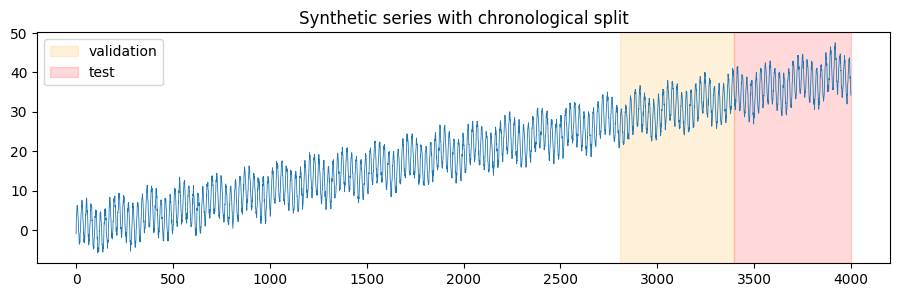

In [ ]:
T = 4000
t = np.arange(T)
series = (0.01 * t + 5 * np.sin(2 * np.pi * t / 24) + 2 * np.sin(2 * np.pi * t / 168)
          + rng.normal(0, 0.6, T)).astype("float32")

WINDOW, HORIZON = 48, 12
X_ts, y_ts = make_windows(series, WINDOW, HORIZON)
(Xtr, ytr), (Xva, yva), (Xte, yte) = chronological_split(X_ts, y_ts)
scaler_ts = RelativeScaler().fit(Xtr)
Xtr_s, ytr_s = scaler_ts.transform(Xtr, ytr)
Xva_s, yva_s = scaler_ts.transform(Xva, yva)
Xte_s = scaler_ts.transform(Xte)

plt.figure(figsize=(11, 3)); plt.plot(series, lw=0.6)
n_tr, n_va = len(Xtr), len(Xva)
plt.axvspan(n_tr + WINDOW, n_tr + n_va + WINDOW, color="orange", alpha=0.15, label="validation")
plt.axvspan(n_tr + n_va + WINDOW, T, color="red", alpha=0.15, label="test")
plt.title("Synthetic series with chronological split"); plt.legend(); plt.show()


In [ ]:
def seasonal_naive(X, horizon, period=24):
    # Forecast = the value one period earlier (needs window >= period)
    return X[:, -period:-period + horizon, 0] if horizon < period else X[:, -period:, 0][:, :horizon]

ts_results, ts_models = {}, {}
for cell in ["simple", "gru", "lstm"]:
    set_seed()
    m = build_rnn("regression", (WINDOW, 1), cell=cell, units=(64,), n_outputs=HORIZON, name=f"forecast_{cell}")
    fit(m, Xtr_s, ytr_s, (Xva_s, yva_s), max_epochs=60, patience=8)
    p = scaler_ts.inverse_y(Xte, m.predict(Xte_s, verbose=0))
    ts_results[cell] = float(np.mean(np.abs(p - yte)))
    ts_models[cell] = m

ts_results["seasonal naive"] = float(np.mean(np.abs(seasonal_naive(Xte, HORIZON) - yte)))
for k, v in sorted(ts_results.items(), key=lambda kv: kv[1]):
    print(f"{k:<15} test MAE {v:.3f}")

simple          test MAE 0.592
gru             test MAE 0.669
lstm            test MAE 0.669
seasonal naive  test MAE 1.235


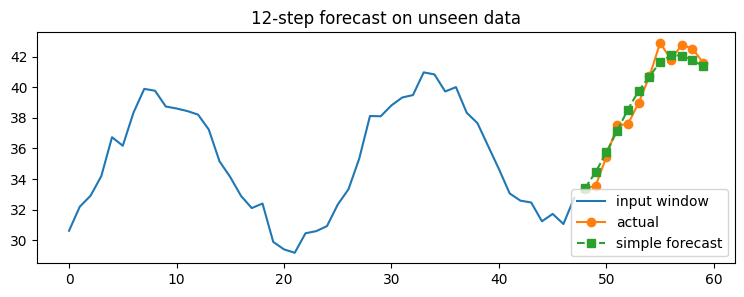

In [ ]:
best_cell = min((k for k in ts_models), key=ts_results.get)
forecaster = ts_models[best_cell]
i = len(Xte) // 2
p = scaler_ts.inverse_y(Xte[i:i + 1], forecaster.predict(Xte_s[i:i + 1], verbose=0))[0]

plt.figure(figsize=(9, 3))
plt.plot(range(WINDOW), Xte[i, :, 0], label="input window")
plt.plot(range(WINDOW, WINDOW + HORIZON), yte[i], "o-", label="actual")
plt.plot(range(WINDOW, WINDOW + HORIZON), p, "s--", label=f"{best_cell} forecast")
plt.title("12-step forecast on unseen data"); plt.legend(); plt.show()

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
400,000 characters | vocabulary 63 | 3,999 training sequences


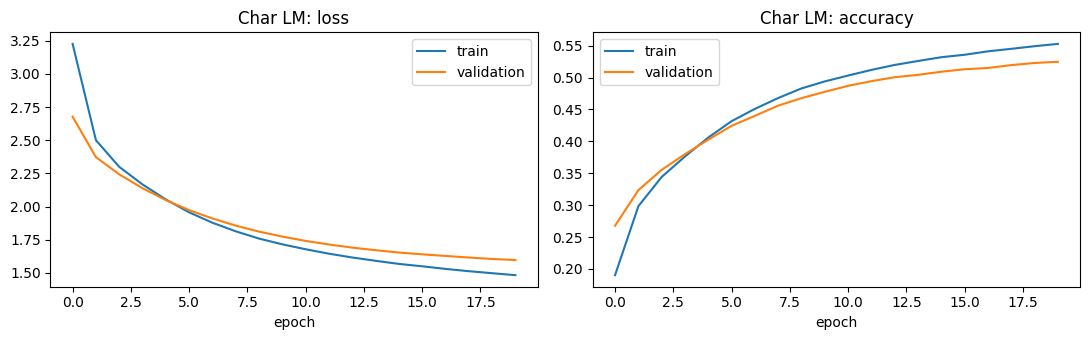

In [ ]:
FALLBACK_TEXT = (
    "the river ran under the old stone bridge, and the town listened to it all night. "
    "in the morning the bakers lit their ovens, the bells rang the hour, and the river ran on. "
    "nobody remembered when the bridge was built, only that it had always been there, "
    "patient and grey, carrying the town from one bank to the other. "
) * 60

try:
    path = keras.utils.get_file("shakespeare.txt",
        "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
    corpus = open(path, encoding="utf-8").read()[:400_000]
except Exception as e:
    print("Download failed, using built-in text:", type(e).__name__)
    corpus = FALLBACK_TEXT

chars = sorted(set(corpus))
char2id = {c: i for i, c in enumerate(chars)}
ids = np.array([char2id[c] for c in corpus], dtype="int32")

SEQ = 100
n_seq = (len(ids) - 1) // SEQ
X_chr = ids[:n_seq * SEQ].reshape(n_seq, SEQ)
y_chr = ids[1:n_seq * SEQ + 1].reshape(n_seq, SEQ)
split = int(0.9 * n_seq)
print(f"{len(corpus):,} characters | vocabulary {len(chars)} | {n_seq:,} training sequences")

set_seed()
char_model = build_rnn("language_model", cell="gru", units=(256,), vocab_size=len(chars),
                       embed_dim=64, dropout=0.1, name="char_gru")
h_chr = fit(char_model, X_chr[:split], y_chr[:split], (X_chr[split:], y_chr[split:]),
            max_epochs=20, patience=3, batch_size=64)
plot_history(h_chr, "Char LM:")

In [ ]:
def generate(model, seed_text, n_chars=500, temperature=0.8, context=SEQ):
    # Map characters in seed text to their corresponding integer IDs
    ids_list = [char2id.get(c, 0) for c in seed_text]

    # Reverse mapping dictionary to turn IDs back into characters
    id2char = {i: c for c, i in char2id.items()}

    for _ in range(n_chars):
        # Keep only the last 'context' tokens as inputs
        inputs = np.array([ids_list[-context:]], dtype="int32")

        # Get model's prediction logits for the next token
        preds = model.predict(inputs, verbose=0)[0]  # shape: (seq_len, vocab_size)

        # We only care about the predictions for the final character
        next_logits = preds[-1]

        # Scale logits by temperature and convert to probability distribution
        probs = np.exp(next_logits / temperature) / np.sum(np.exp(next_logits / temperature))

        # Sample next token based on calculated probabilities
        next_id = np.random.choice(len(chars), p=probs)
        ids_list.append(next_id)

    return seed_text + "".join(id2char[i] for i in ids_list[len(seed_text):])

# Test generating some Shakespearean text!
print(generate(char_model, "First Citizen:\n"))

First Citizen:
In the too word in life is moliceser,
That well of those ears that thy cause.

BUCKINGHAM:
Upon the book, my compostage to be to
The guess world I langed with the marke,
The people as for the tongues, and Has anmont like of glory.

KING RICHARD III:
I will pigizent; then, where to have men
As I thou hasty done at the fire with fird
A trian consuing to be summents with a sain
That to here? are your virgue
Where me mother and hand a past at his:
Sen our Ough our fathers too lost of them?

CORIOLAN


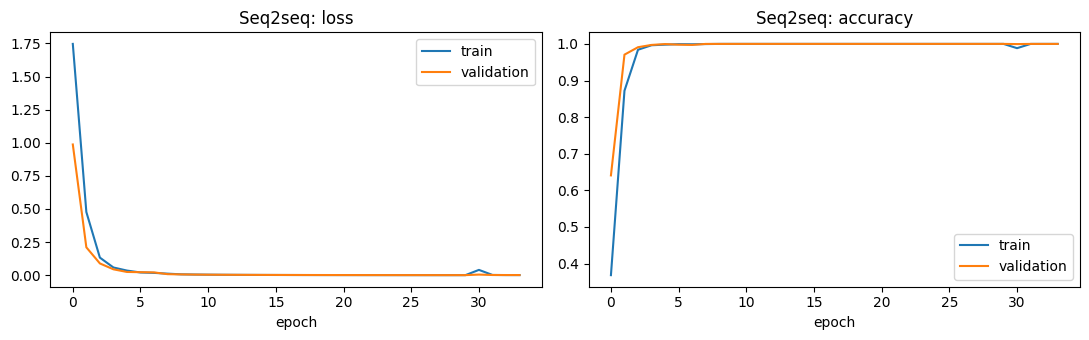

Exact-match accuracy on 500 unseen sequences: 100.0%
input 5837879 -> output 9787385
input 8399099 -> output 9909938
input 8981020 -> output 0201898


In [ ]:
#RNN Encoder Decoder Execution
PAD, START, END = 0, 1, 2
DIGIT0, N_TOK = 3, 13          # tokens 3..12 are the digits 0..9
SRC_LEN = 7

def reversal_data(n):
    digits = rng.integers(0, 10, size=(n, SRC_LEN)) + DIGIT0
    target = digits[:, ::-1]
    dec_in = np.concatenate([np.full((n, 1), START), target], axis=1)
    dec_out = np.concatenate([target, np.full((n, 1), END)], axis=1)
    return digits.astype("int32"), dec_in.astype("int32"), dec_out.astype("int32")

def build_seq2seq(units=128, embed=32):
    enc_in = keras.Input((None,), dtype="int32", name="encoder_tokens")
    _, h, c = layers.LSTM(units, return_state=True)(layers.Embedding(N_TOK, embed)(enc_in))

    dec_in = keras.Input((None,), dtype="int32", name="decoder_tokens")
    dec_emb = layers.Embedding(N_TOK, embed)
    dec_lstm = layers.LSTM(units, return_sequences=True, return_state=True)
    dec_dense = layers.Dense(N_TOK)
    y, _, _ = dec_lstm(dec_emb(dec_in), initial_state=[h, c])
    train_model = keras.Model([enc_in, dec_in], dec_dense(y), name="seq2seq")
    train_model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
                        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                        metrics=["accuracy"])

    # inference models share the trained layers
    encoder = keras.Model(enc_in, [h, c])
    sh, sc = keras.Input((units,)), keras.Input((units,))
    y2, h2, c2 = dec_lstm(dec_emb(dec_in), initial_state=[sh, sc])
    decoder = keras.Model([dec_in, sh, sc], [dec_dense(y2), h2, c2])
    return train_model, encoder, decoder

def greedy_decode(encoder, decoder, src, max_len=SRC_LEN + 1):
    h, c = encoder.predict(src, verbose=0)
    tok = np.full((len(src), 1), START, dtype="int32")
    out = []
    for _ in range(max_len):
        logits, h, c = decoder.predict([tok, h, c], verbose=0)
        tok = logits[:, -1].argmax(-1).astype("int32")[:, None]
        out.append(tok[:, 0])
    return np.stack(out, axis=1)

set_seed()
src_tr, din_tr, dout_tr = reversal_data(20000)
src_va, din_va, dout_va = reversal_data(2000)
s2s, s2s_enc, s2s_dec = build_seq2seq()
h_s2s = fit(s2s, [src_tr, din_tr], dout_tr, ([src_va, din_va], dout_va), max_epochs=40, patience=4, batch_size=128)
plot_history(h_s2s, "Seq2seq:")

src_te, _, dout_te = reversal_data(500)
decoded = greedy_decode(s2s_enc, s2s_dec, src_te)
exact = np.mean(np.all(decoded == dout_te, axis=1))
print(f"Exact-match accuracy on 500 unseen sequences: {exact:.1%}")
to_str = lambda seq: "".join(str(t - DIGIT0) for t in seq if t >= DIGIT0)
for i in range(3):
    print(f"input {to_str(src_te[i])} -> output {to_str(decoded[i])}")

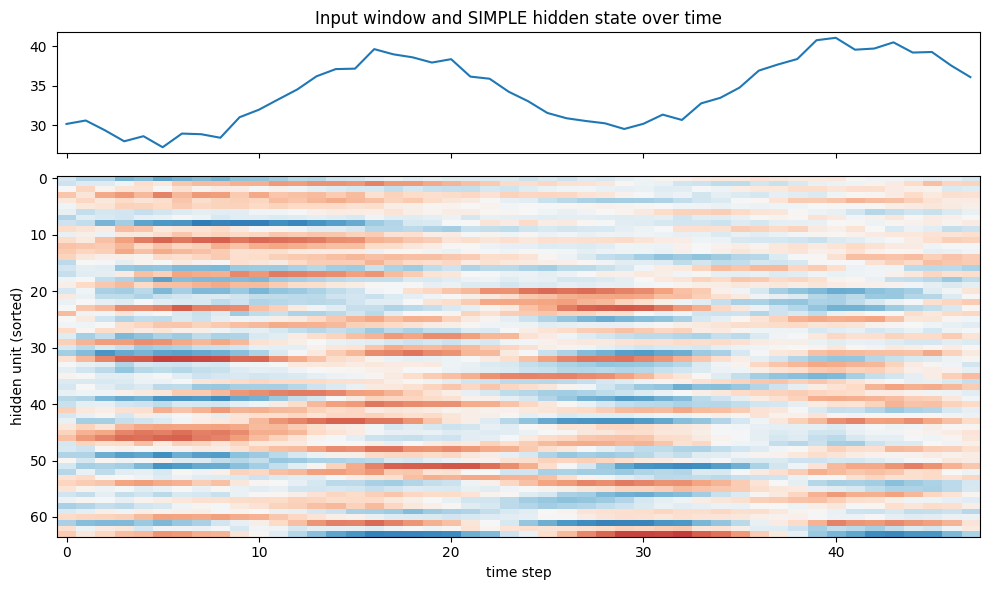

In [ ]:
def hidden_states(model, X):
    # Return the first recurrent layer's state at every time step: (n, time, units).
    rnn = next(l for l in model.layers if isinstance(l, (layers.SimpleRNN, layers.LSTM, layers.GRU)))
    probe_layer = type(rnn).from_config({**rnn.get_config(), "return_sequences": True, "name": "probe"})
    inp = keras.Input(shape=model.input_shape[1:])
    probe = keras.Model(inp, probe_layer(inp))
    probe_layer.set_weights(rnn.get_weights())
    return probe.predict(X, verbose=0)

H = hidden_states(forecaster, Xte_s[:1])[0]                     # (48, units)
order = np.argsort(np.argmax(np.abs(np.fft.rfft(H, axis=0))[1:], axis=0))   # group units by dominant rhythm

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
a1.plot(Xte[0, :, 0]); a1.set_title(f"Input window and {best_cell.upper()} hidden state over time")
a2.imshow(H[:, order].T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
a2.set_xlabel("time step"); a2.set_ylabel("hidden unit (sorted)")
plt.tight_layout(); plt.show()

### 4. Classical Machine Learning Models for Time Series Forecasting

Traditional machine learning models require a 2D tabular structure instead of the 3D structure `(samples, time_steps, features)` expected by recurrent networks. Let's flatten our input features and train:
1. **Linear Regression** (Ordinary Least Squares)
2. **Random Forest Regressor**
3. **Gradient Boosting Regressor** (Gradient Descent tree-boosting under the hood)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

# Flatten the 3D window inputs to 2D tabular formats: (samples, WINDOW * features)
# Note: since features dimension is 1, we can simply squeeze or reshape.
Xtr_ml = Xtr_s.reshape(Xtr_s.shape[0], -1)
Xva_ml = Xva_s.reshape(Xva_s.shape[0], -1)
Xte_ml = Xte_s.reshape(Xte_s.shape[0], -1)

# Targets are already 2D (samples, HORIZON)
ytr_ml = ytr_s
yte_ml = yva_s # scaled validation targets or comparison targets

print(f"FLattened Train shape: {Xtr_ml.shape}")
print(f"Target Train shape: {ytr_ml.shape}")

FLattened Train shape: (2758, 48)
Target Train shape: (2758, 12)


In [ ]:
# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(Xtr_ml, ytr_ml)
lr_preds_scaled = lr_model.predict(Xte_ml)
lr_preds = scaler_ts.inverse_y(Xte, lr_preds_scaled)
lr_mae = float(np.mean(np.abs(lr_preds - yte)))

# 2. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(Xtr_ml, ytr_ml)
rf_preds_scaled = rf_model.predict(Xte_ml)
rf_preds = scaler_ts.inverse_y(Xte, rf_preds_scaled)
rf_mae = float(np.mean(np.abs(rf_preds - yte)))

# 3. Gradient Boosting (Multi-output wrapper is required since Gradient Boosting only handles 1D targets)
gb_model = MultiOutputRegressor(GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
gb_model.fit(Xtr_ml, ytr_ml)
gb_preds_scaled = gb_model.predict(Xte_ml)
gb_preds = scaler_ts.inverse_y(Xte, gb_preds_scaled)
gb_mae = float(np.mean(np.abs(gb_preds - yte)))

print(f"Linear Regression test MAE:   {lr_mae:.3f}")
print(f"Random Forest test MAE:       {rf_mae:.3f}")
print(f"Gradient Boosting test MAE:   {gb_mae:.3f}")

Linear Regression test MAE:   0.558
Random Forest test MAE:       0.632
Gradient Boosting test MAE:   0.661


In [ ]:
# Compare with RNN models
for k, v in sorted(ts_results.items(), key=lambda kv: kv[1]):
    print(f"RNN {k:<15} test MAE {v:.3f}")

RNN simple          test MAE 0.592
RNN gru             test MAE 0.669
RNN lstm            test MAE 0.669
RNN seasonal naive  test MAE 1.235


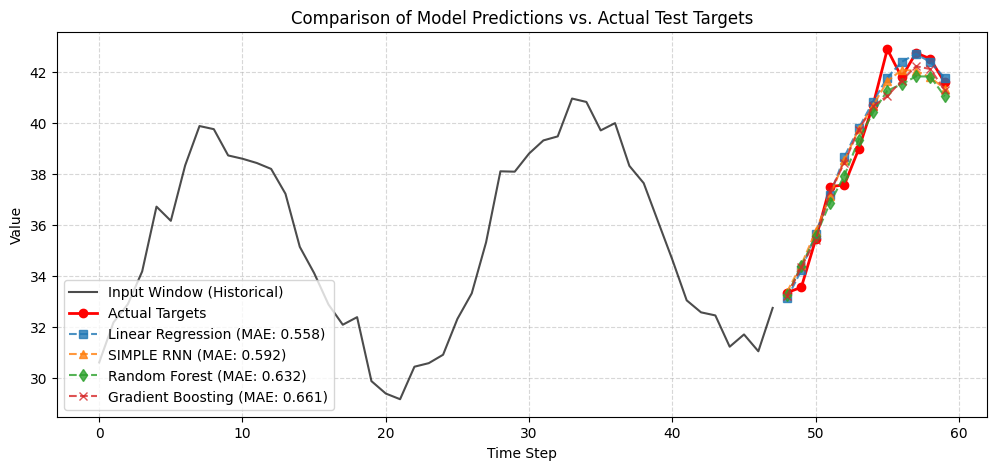

In [ ]:
import matplotlib.pyplot as plt

# Select a sample index from the test set
sample_idx = len(Xte) // 2

# Get predictions for this specific sample
lr_sample = lr_preds[sample_idx]
rf_sample = rf_preds[sample_idx]
gb_sample = gb_preds[sample_idx]
rnn_sample = scaler_ts.inverse_y(Xte[sample_idx:sample_idx + 1], forecaster.predict(Xte_s[sample_idx:sample_idx + 1], verbose=0))[0]
actual = yte[sample_idx]

# Plot the input history and the various predictions
plt.figure(figsize=(12, 5))
plt.plot(range(WINDOW), Xte[sample_idx, :, 0], label="Input Window (Historical)", color="black", alpha=0.7, linewidth=1.5)
plt.plot(range(WINDOW, WINDOW + HORIZON), actual, "o-", label="Actual Targets", color="red", linewidth=2)
plt.plot(range(WINDOW, WINDOW + HORIZON), lr_sample, "s--", label=f"Linear Regression (MAE: {lr_mae:.3f})", alpha=0.8)
plt.plot(range(WINDOW, WINDOW + HORIZON), rnn_sample, "^--", label=f"{best_cell.upper()} RNN (MAE: {ts_results[best_cell]:.3f})", alpha=0.8)
plt.plot(range(WINDOW, WINDOW + HORIZON), rf_sample, "d--", label=f"Random Forest (MAE: {rf_mae:.3f})", alpha=0.8)
plt.plot(range(WINDOW, WINDOW + HORIZON), gb_sample, "x--", label=f"Gradient Boosting (MAE: {gb_mae:.3f})", alpha=0.8)

plt.title("Comparison of Model Predictions vs. Actual Test Targets")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

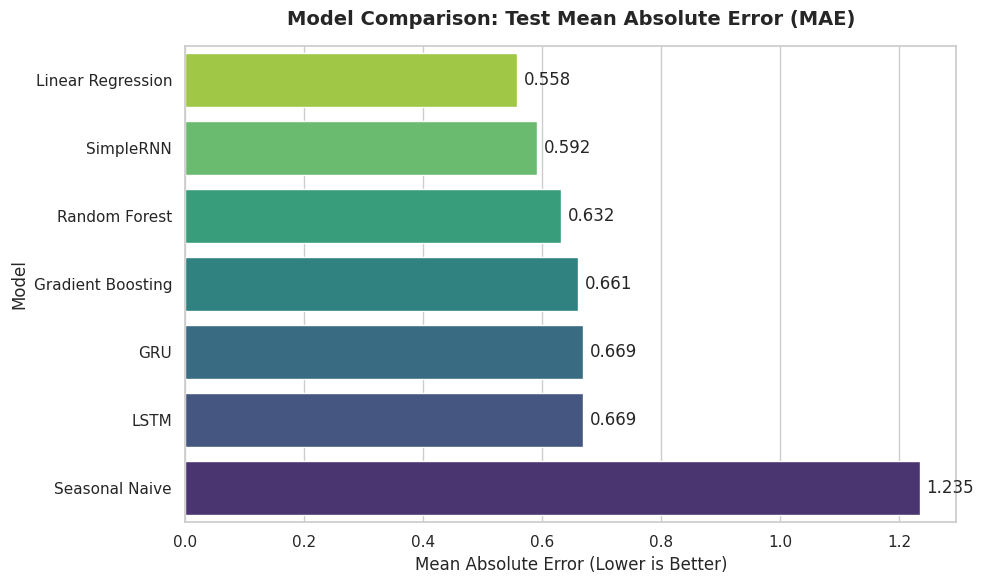

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Prepare the data dictionary with all results
results_data = {
    "Model": [
        "Linear Regression",
        "SimpleRNN",
        "Random Forest",
        "Gradient Boosting",
        "GRU",
        "LSTM",
        "Seasonal Naive"
    ],
    "Test MAE": [
        lr_mae,
        ts_results["simple"],
        rf_mae,
        gb_mae,
        ts_results["gru"],
        ts_results["lstm"],
        ts_results["seasonal naive"]
    ]
}

# Convert to DataFrame
df_results = pd.DataFrame(results_data).sort_values(by="Test MAE")

# Set seaborn aesthetic style
sns.set_theme(style="whitegrid")

# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a barplot sorted by error (lower is better)
ax = sns.barplot(
    x="Test MAE",
    y="Model",
    data=df_results,
    hue="Model",
    palette="viridis_r",
    legend=False
)

# Add values on the bar edges
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=5)

# Customize labels and title
plt.title("Model Comparison: Test Mean Absolute Error (MAE)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Mean Absolute Error (Lower is Better)", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.tight_layout()
plt.show()

### 5. Advanced Visualizations: KDE Plot & Clustermap

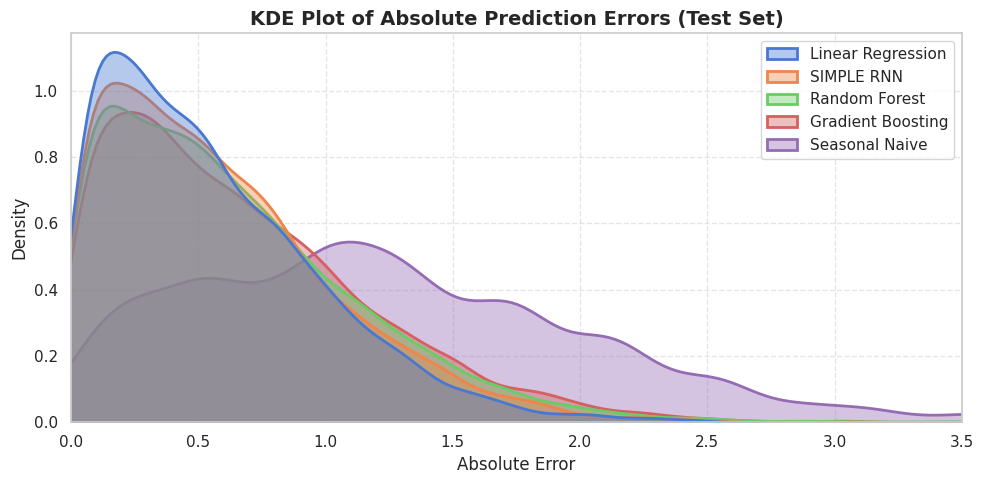

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Calculate Absolute Errors for each prediction step ---
# Flattening to compare element-wise across all test samples and steps
lr_errors = np.abs(lr_preds - yte).flatten()
rnn_errors = np.abs(scaler_ts.inverse_y(Xte, ts_models[best_cell].predict(Xte_s, verbose=0)) - yte).flatten()
rf_errors = np.abs(rf_preds - yte).flatten()
gb_errors = np.abs(gb_preds - yte).flatten()
naive_errors = np.abs(seasonal_naive(Xte, HORIZON) - yte).flatten()

# Create a DataFrame for KDE plotting
error_df = pd.DataFrame({
    'Linear Regression': lr_errors,
    f'{best_cell.upper()} RNN': rnn_errors,
    'Random Forest': rf_errors,
    'Gradient Boosting': gb_errors,
    'Seasonal Naive': naive_errors
})

# Plotting KDE of Absolute Errors
plt.figure(figsize=(10, 5))
sns.kdeplot(data=error_df, fill=True, common_norm=False, palette='muted', alpha=0.4, linewidth=2)
plt.title("KDE Plot of Absolute Prediction Errors (Test Set)", fontsize=14, fontweight='bold')
plt.xlabel("Absolute Error", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, 3.5) # Focus on the region where most errors reside
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

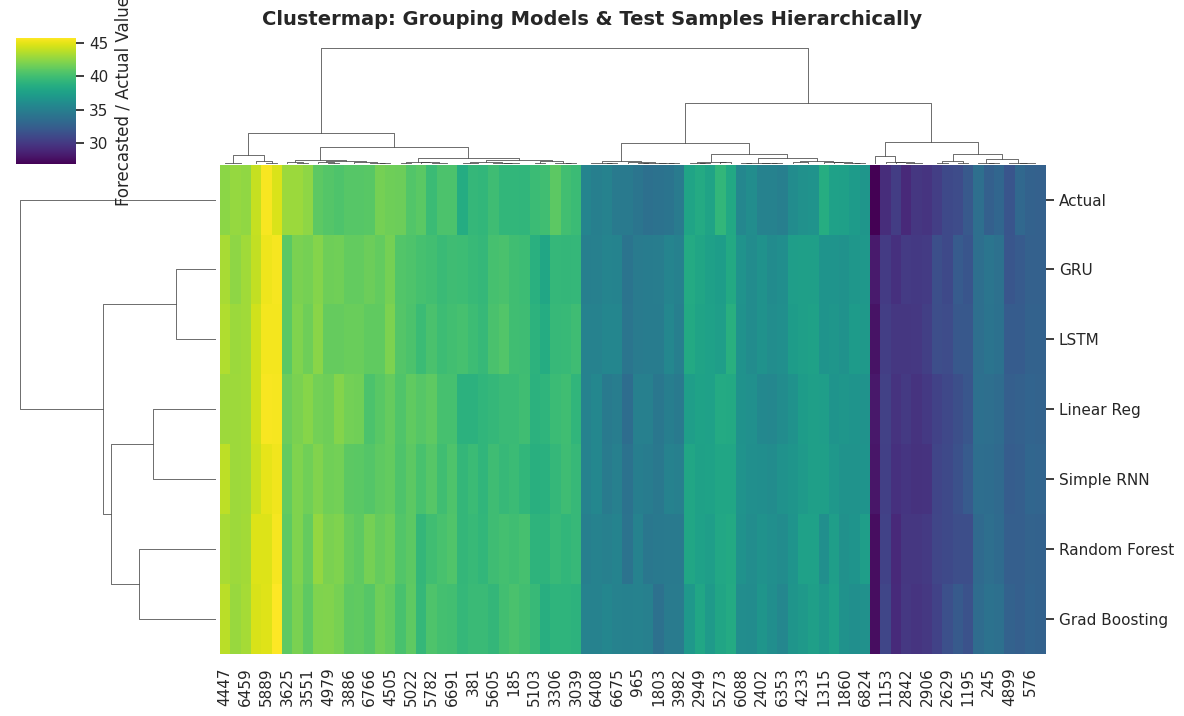

In [ ]:
# --- 2. Hierarchical Clustermap of Model Predictions ---
# Let's see how similar the model prediction structures are to each other.
# We will select 100 random forecast steps from the test set for a clean visualization.

np.random.seed(42)
all_preds_flat = {
    'Actual': yte.flatten(),
    'Linear Reg': lr_preds.flatten(),
    'Simple RNN': scaler_ts.inverse_y(Xte, ts_models['simple'].predict(Xte_s, verbose=0)).flatten(),
    'GRU': scaler_ts.inverse_y(Xte, ts_models['gru'].predict(Xte_s, verbose=0)).flatten(),
    'LSTM': scaler_ts.inverse_y(Xte, ts_models['lstm'].predict(Xte_s, verbose=0)).flatten(),
    'Random Forest': rf_preds.flatten(),
    'Grad Boosting': gb_preds.flatten()
}

pred_df = pd.DataFrame(all_preds_flat)
sample_indices = np.random.choice(pred_df.index, size=80, replace=False)
sampled_preds = pred_df.loc[sample_indices]

# Generate Clustermap (correlating the models and clustering the test samples)
cg = sns.clustermap(
    sampled_preds.T,
    cmap='viridis',
    metric='euclidean',
    method='ward',
    figsize=(12, 7),
    cbar_kws={'label': 'Forecasted / Actual Value'}
)
cg.fig.suptitle("Clustermap: Grouping Models & Test Samples Hierarchically", fontsize=14, fontweight='bold', y=1.02)
plt.show()

### 6. Complementary Diagnostics: Lineplot, Relplot, & Boxplot
We will inspect the underlying synthetic signal components and evaluate how absolute error scales across the 12-step predictive horizon.

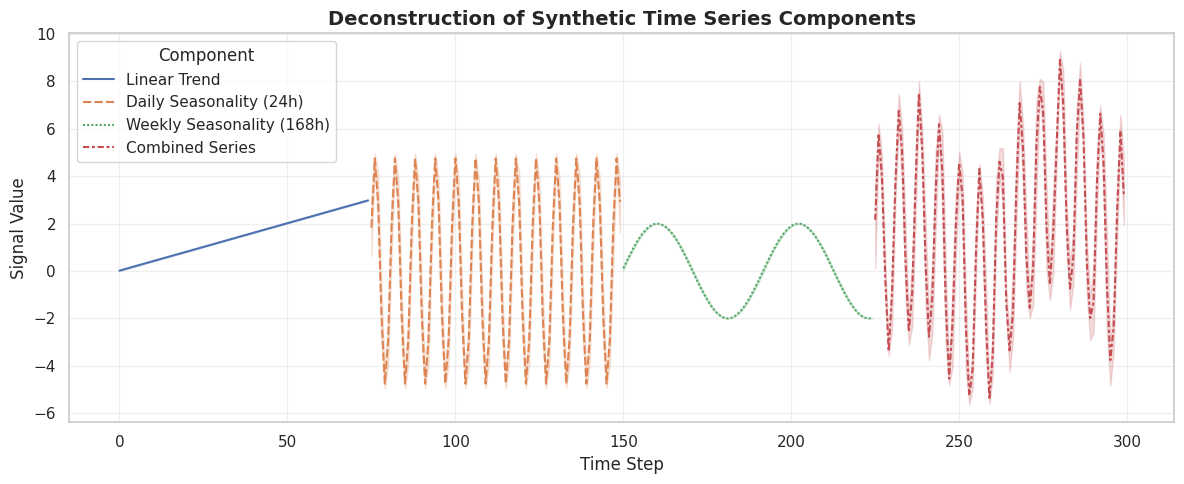

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Lineplot: Deconstruct the Time Series Signal Components ---
# Let's inspect the trend and seasonal components over a subset of the first 300 steps
t_subset = t[:300]
trend_comp = 0.01 * t_subset
sea_24 = 5 * np.sin(2 * np.pi * t_subset / 24)
sea_168 = 2 * np.sin(2 * np.pi * t_subset / 168)
noise = rng.normal(0, 0.6, len(t_subset))

comp_df = pd.DataFrame({
    'Time Step': np.repeat(t_subset, 4),
    'Value': np.concatenate([trend_comp, sea_24, sea_168, series[:300]]),
    'Component': (['Linear Trend'] * len(t_subset) +
                  ['Daily Seasonality (24h)'] * len(t_subset) +
                  ['Weekly Seasonality (168h)'] * len(t_subset) +
                  ['Combined Series'] * len(t_subset))
})

plt.figure(figsize=(12, 5))
sns.lineplot(data=comp_df, x='Time Step', y='Value', hue='Component', style='Component', linewidth=1.5)
plt.title("Deconstruction of Synthetic Time Series Components", fontsize=14, fontweight='bold')
plt.ylabel("Signal Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

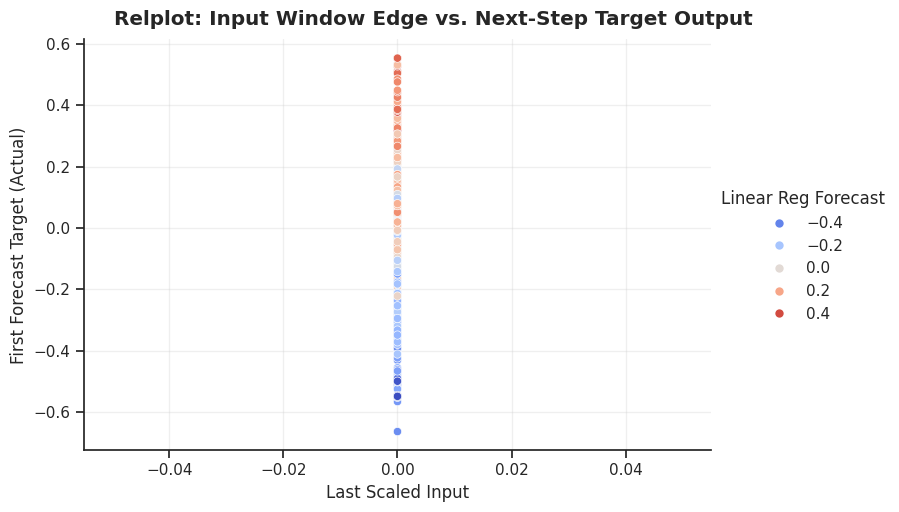

In [ ]:
# --- 2. Relplot: Relationship between Last Input Step vs First Step Forecast ---
# Let us align our test inputs and test targets appropriately
te_targets_scaled = scaler_ts.transform(Xte, yte)[1]

rel_df = pd.DataFrame({
    'Last Scaled Input': Xte_s[:, -1, 0],
    'First Forecast Target (Actual)': te_targets_scaled[:, 0],
    'Linear Reg Forecast': lr_preds_scaled[:, 0],
    'Simple RNN Forecast': ts_models['simple'].predict(Xte_s, verbose=0)[:, 0]
})

sns.set_theme(style="ticks")
g = sns.relplot(
    data=rel_df,
    x="Last Scaled Input",
    y="First Forecast Target (Actual)",
    hue="Linear Reg Forecast",
    palette="coolwarm",
    aspect=1.5,
    height=5
)
g.fig.suptitle("Relplot: Input Window Edge vs. Next-Step Target Output", y=1.02, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

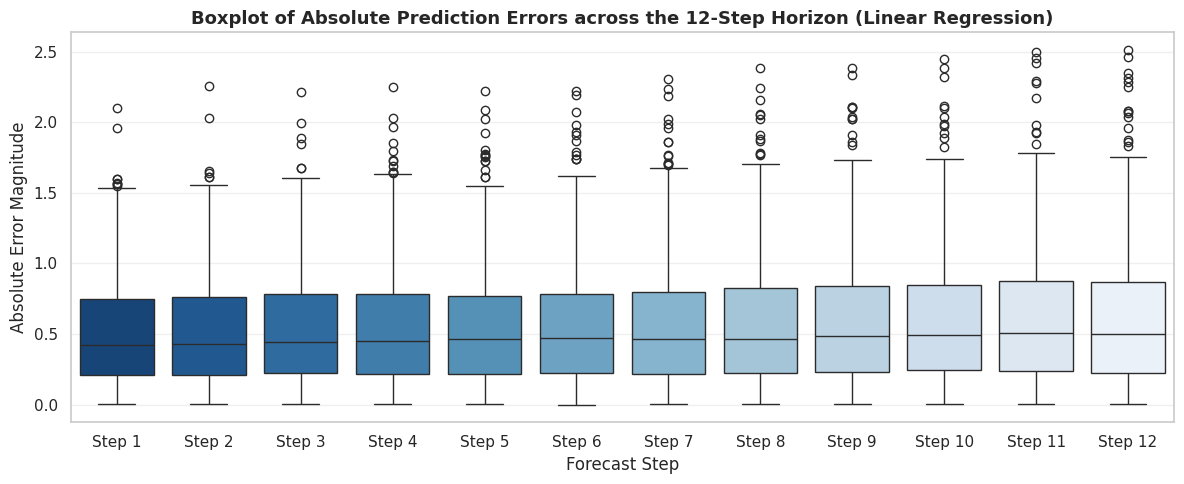

In [ ]:
# --- 3. Boxplot: Absolute Errors Distributed Across the 12 Forecast Steps ---
# We want to see how prediction error behaves as we step further out into the horizon (Steps 1 to 12)
lr_step_errors = np.abs(lr_preds - yte)  # shape: (n_samples, 12)

# Format for Seaborn
step_error_df = pd.DataFrame(lr_step_errors, columns=[f"Step {i+1}" for i in range(HORIZON)])
step_error_melted = step_error_df.melt(var_name='Forecast Step', value_name='Absolute Error')

plt.figure(figsize=(12, 5))
sns.boxplot(data=step_error_melted, x='Forecast Step', y='Absolute Error', palette='Blues_r', hue='Forecast Step', legend=False)
plt.title("Boxplot of Absolute Prediction Errors across the 12-Step Horizon (Linear Regression)", fontsize=13, fontweight='bold')
plt.ylabel("Absolute Error Magnitude")
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

```markdown
### 7. Paired Density and Scatterplot Matrix of Horizon Errors
To investigate the correlation structures and marginal densities of prediction errors as we forecast further out, let's create a paired density and scatterplot matrix using `seaborn.pairplot` across several steps of our 12-step predictive horizon.
```

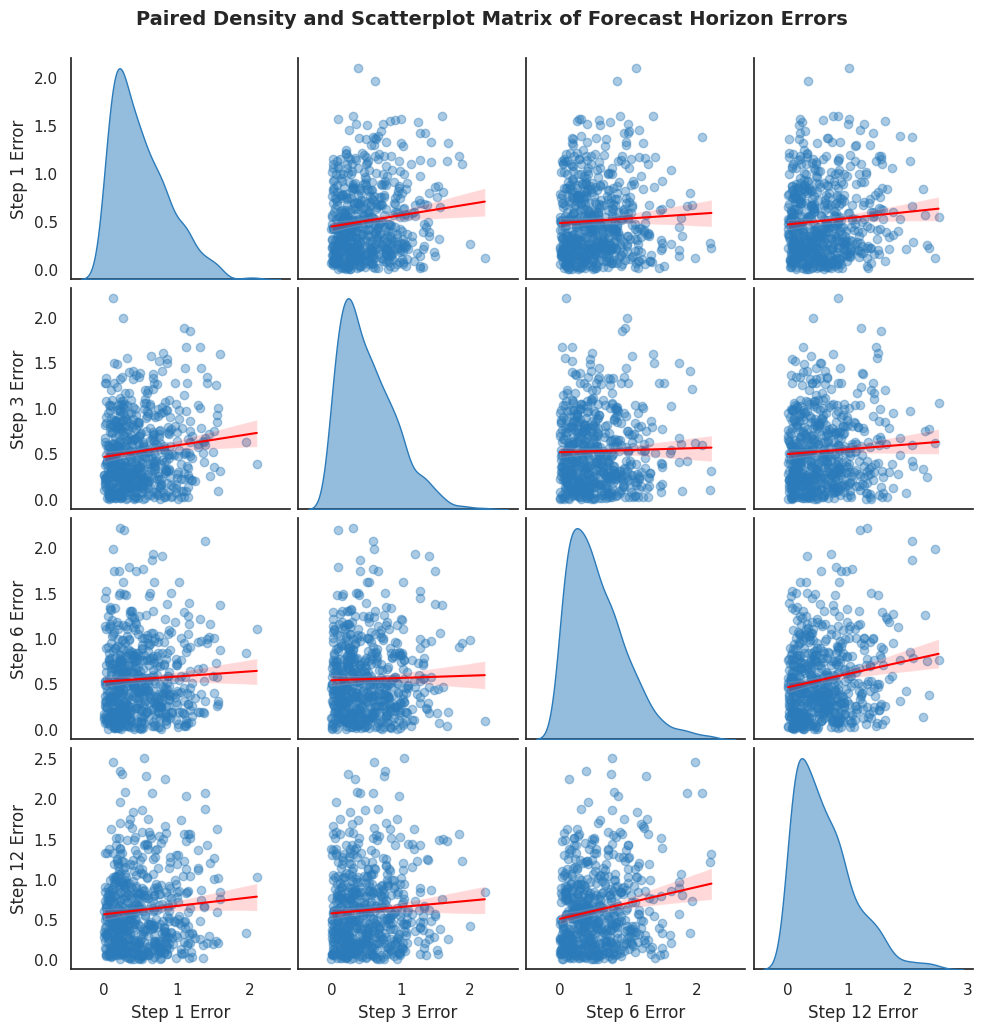

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# select steps of interest to keep the matrix clean and interpretable
selected_steps = [0, 2, 5, 11] # Steps 1, 3, 6, and 12

# Extract absolute errors for these steps from our top baseline model (Linear Regression)
selected_errors_df = pd.DataFrame(
    lr_step_errors[:, selected_steps],
    columns=[f"Step {i+1} Error" for i in selected_steps]
)

# Configure a clean aesthetic context for Seaborn
sns.set_theme(style="white")

# Create a pairwise density and scatterplot matrix
g = sns.pairplot(
    selected_errors_df,
    diag_kind="kde",
    kind="reg",
    plot_kws={'scatter_kws': {'alpha': 0.4, 'color': '#2b7bba'}, 'line_kws': {'color': 'red', 'linewidth': 1.5}},
    diag_kws={'fill': True, 'color': '#2b7bba', 'alpha': 0.5}
)

g.fig.suptitle("Paired Density and Scatterplot Matrix of Forecast Horizon Errors", y=1.03, fontsize=14, fontweight='bold')
plt.show()

### 8. Bivariate KDE Diagnostics
Let's plot bivariate Kernel Density Estimate (KDE) plots to visualize the joint probability distributions and density contours of absolute prediction errors between early, mid, and late steps in the forecast horizon.

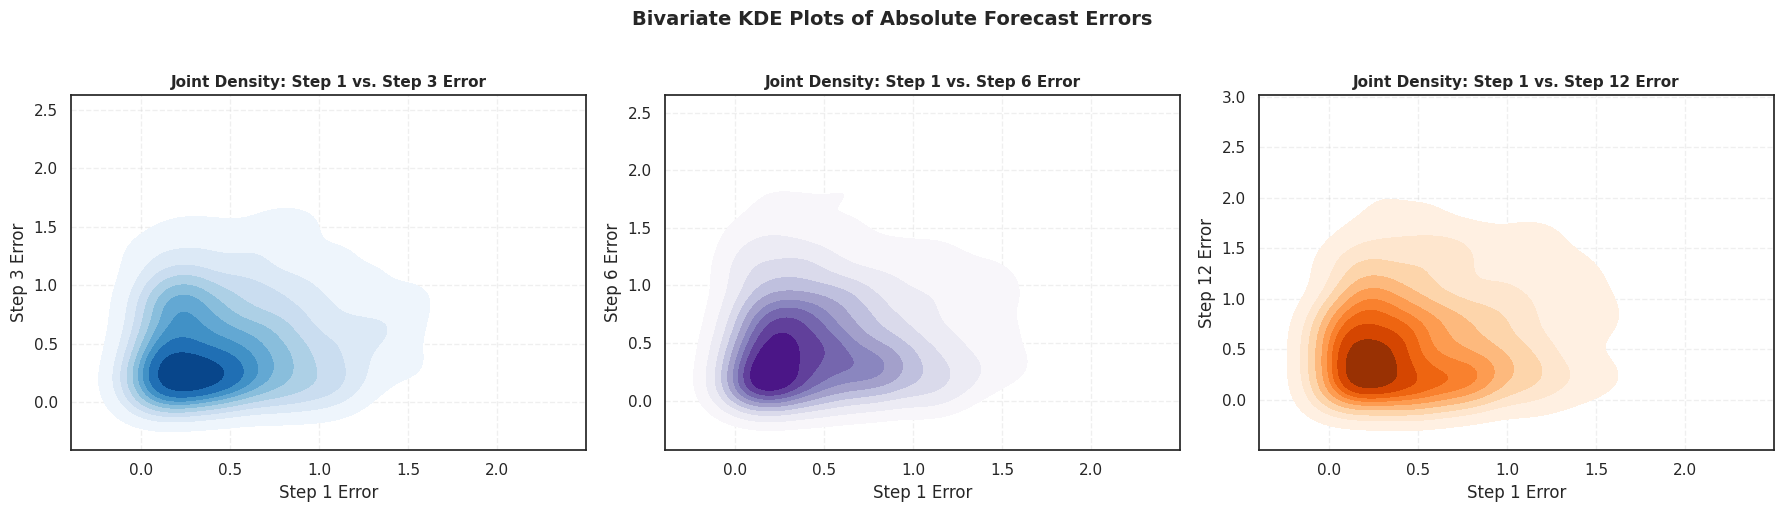

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up a grid of bivariate density plots to contrast different steps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Step 1 vs Step 3
sns.kdeplot(
    data=selected_errors_df,
    x="Step 1 Error",
    y="Step 3 Error",
    fill=True,
    cmap="Blues",
    thresh=0.05,
    ax=axes[0]
)
axes[0].set_title("Joint Density: Step 1 vs. Step 3 Error", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Step 1 vs Step 6
sns.kdeplot(
    data=selected_errors_df,
    x="Step 1 Error",
    y="Step 6 Error",
    fill=True,
    cmap="Purples",
    thresh=0.05,
    ax=axes[1]
)
axes[1].set_title("Joint Density: Step 1 vs. Step 6 Error", fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Step 1 vs Step 12
sns.kdeplot(
    data=selected_errors_df,
    x="Step 1 Error",
    y="Step 12 Error",
    fill=True,
    cmap="Oranges",
    thresh=0.05,
    ax=axes[2]
)
axes[2].set_title("Joint Density: Step 1 vs. Step 12 Error", fontsize=11, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.suptitle("Bivariate KDE Plots of Absolute Forecast Errors", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


```markdown
### 9. Conditional Kernel Density Estimates
To understand the propagation of uncertainty, we can visualize the *conditional* probability density of the late-horizon error (Step 12) given different levels of the initial error (Step 1). We divide the Step 1 Error into three tiers (Low, Medium, High) using quantiles and plot the conditional KDE of the Step 12 Error.
```

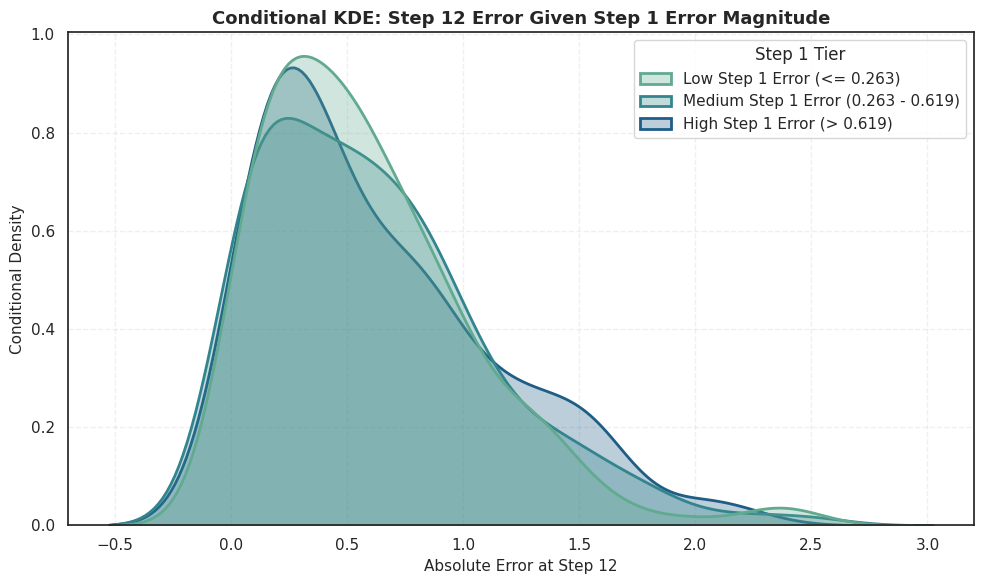

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create categories for Step 1 Error using quantiles
q33, q66 = selected_errors_df["Step 1 Error"].quantile([1/3, 2/3])

def categorize_step1(err):
    if err <= q33:
        return f"Low Step 1 Error (<= {q33:.3f})"
    elif err <= q66:
        return f"Medium Step 1 Error ({q33:.3f} - {q66:.3f})"
    else:
        return f"High Step 1 Error (> {q66:.3f})"

# Apply categorization
conditional_df = selected_errors_df.copy()
conditional_df["Step 1 Tier"] = conditional_df["Step 1 Error"].apply(categorize_step1)

# Plot conditional KDEs
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=conditional_df,
    x="Step 12 Error",
    hue="Step 1 Tier",
    hue_order=[
        f"Low Step 1 Error (<= {q33:.3f})",
        f"Medium Step 1 Error ({q33:.3f} - {q66:.3f})",
        f"High Step 1 Error (> {q66:.3f})"
    ],
    fill=True,
    alpha=0.3,
    common_norm=False,
    palette="crest",
    linewidth=2
)

plt.title("Conditional KDE: Step 12 Error Given Step 1 Error Magnitude", fontsize=13, fontweight='bold')
plt.xlabel("Absolute Error at Step 12", fontsize=11)
plt.ylabel("Conditional Density", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()